#### HealthConnect Clinic: Final Analytics & Decision Support Notebook
**Track:** Data Analytics  
**Stage:** Week 8 (Final Integration & Project Showcase)  
**Pod:** HC-POD 4

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# set clean visual style
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


#### Data Loading & Cleaning

In [2]:
# 1. load the cleaned dataset
df = pd.read_csv("HealthConnect_Appointment_Data_Cleaned.csv")

# 2. partition active and cancelled records
active_df = df[df["appointment_outcome"] != "Cancelled"].copy()
cancelled_df = df[df["appointment_outcome"] == "Cancelled"].copy()

# 3. create binary target column for analysis
active_df["is_no_show"] = (active_df["appointment_outcome"] == "No-Show").astype(int)

print(f"Total Records: {len(df)}")
print(f"Active Appointments: {len(active_df)}")
print(f"Cancelled Appointments: {len(cancelled_df)}")

Total Records: 5000
Active Appointments: 4737
Cancelled Appointments: 263


#### Automated Data & KPI Assertions

In [3]:
# assertion 1: total row reconciliation
assert len(active_df) + len(cancelled_df) == 5000, "Row count reconciliation failed."

# assertion 2: target class integrity
assert set(active_df["appointment_outcome"].unique()) == {"Attended", "No-Show"}, "Unexpected outcome found."

# assertion 3: baseline no-show rate check
total_no_shows = active_df["is_no_show"].sum()
baseline_no_show_rate = (total_no_shows / len(active_df)) * 100
assert round(baseline_no_show_rate, 2) == 51.15, "Baseline KPI calculation discrepancy."

# assertion 4: reminder attendance lift check
reminded_attended_rate = (
    active_df[active_df["reminder_sent"] == "Yes"]["appointment_outcome"]
    .value_counts(normalize=True)["Attended"] * 100
)
unreminded_attended_rate = (
    active_df[active_df["reminder_sent"] == "No"]["appointment_outcome"]
    .value_counts(normalize=True)["Attended"] * 100
)
attendance_lift = reminded_attended_rate - unreminded_attended_rate
assert round(attendance_lift, 2) == 4.78, "Reminder lift calculation discrepancy."

print("All automated unit assertions passed successfully (0 errors).")
print(f"Verified Baseline No-Show Rate: {baseline_no_show_rate:.2f}%")
print(f"Verified Reminder Attendance Lift: +{attendance_lift:.2f}%")

All automated unit assertions passed successfully (0 errors).
Verified Baseline No-Show Rate: 51.15%
Verified Reminder Attendance Lift: +4.78%


#### Lead Time Segmentation Analysis

In [4]:
# 1. define lead time bins
bins = [0, 7, 14, 30, 45, 60]
labels = ["0-7 Days", "8-14 Days", "15-30 Days", "31-45 Days", "46-60 Days"]

active_df["lead_bracket"] = pd.cut(
    active_df["booking_lead_days"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# 2. aggregate failure rates by bracket
lead_summary = (
    active_df.groupby("lead_bracket", observed=False)["is_no_show"]
    .agg(Total="count", No_Shows="sum", No_Show_Rate=lambda x: x.mean() * 100)
    .reset_index()
)

# 3. assertion: verify lead time monotonic risk progression
assert lead_summary.loc[0, "No_Show_Rate"] < lead_summary.loc[4, "No_Show_Rate"], "Lead time trend logic error."

print("Lead Time Risk Summary:")
print(lead_summary)

Lead Time Risk Summary:
  lead_bracket  Total  No_Shows  No_Show_Rate
0     0-7 Days    604       178     29.470199
1    8-14 Days    574       202     35.191638
2   15-30 Days   1265       576     45.533597
3   31-45 Days   1187       677     57.034541
4   46-60 Days   1107       790     71.364047


#### Follow-Up Consultation & Channel Analysis

In [5]:
# 1. filter for follow-up appointments
followup_df = active_df[active_df["appointment_type"] == "Follow-up"].copy()

# 2. calculate no-show rate across channels
fu_channel = (
    followup_df.groupby("reminder_channel")["is_no_show"]
    .agg(Total="count", No_Shows="sum", No_Show_Rate=lambda x: x.mean() * 100)
    .reset_index()
)

# 3. overall follow-up average failure rate
followup_avg = (followup_df["is_no_show"].mean()) * 100

print(f"Follow-Up Service Average No-Show Rate: {followup_avg:.2f}%\n")
print("Follow-Up Performance by Channel:")
print(fu_channel)

Follow-Up Service Average No-Show Rate: 54.17%

Follow-Up Performance by Channel:
  reminder_channel  Total  No_Shows  No_Show_Rate
0            Email    132        82     62.121212
1              SMS    560       275     49.107143
2         WhatsApp    295       167     56.610169


#### Generate Final Benchmarked Visualizations

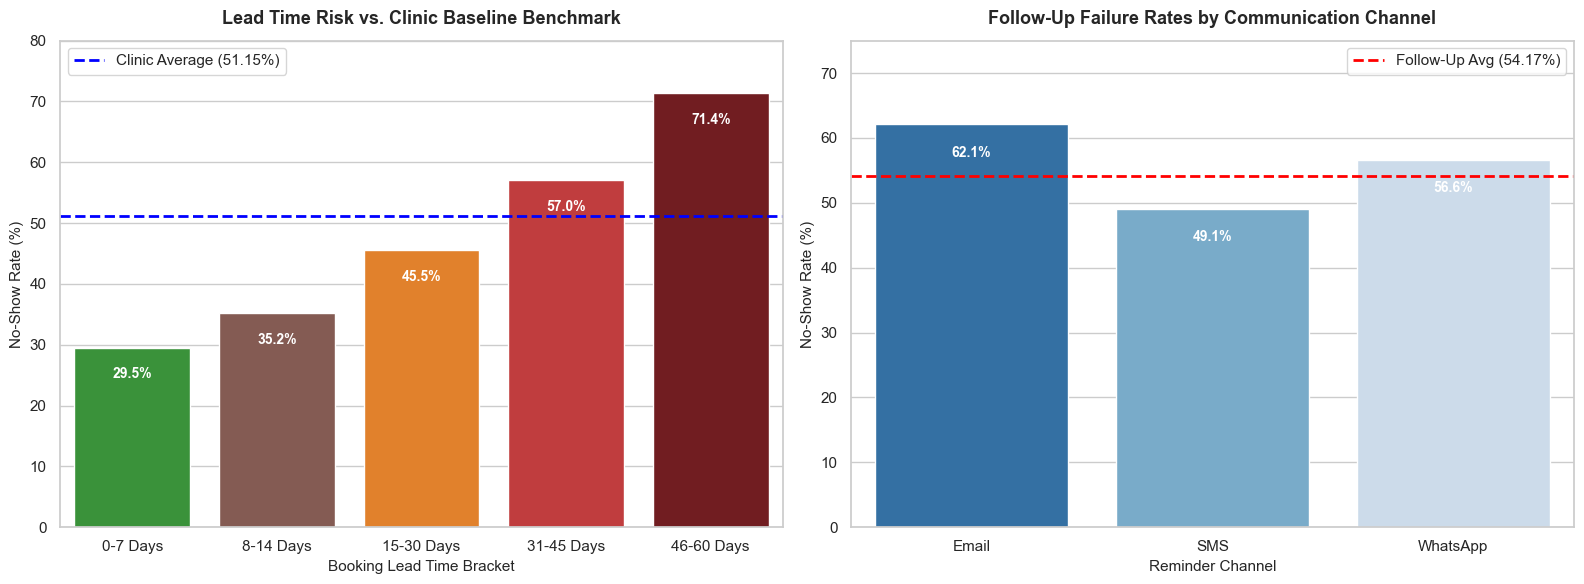

Final benchmarked visual saved successfully: healthconnect_refined_charts.png


In [6]:
# setup figure with 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# chart 1: lead time risk vs clinic baseline 
lead_colors = ["#2ca02c", "#8c564b", "#ff7f0e", "#d62728", "#7f0f15"]

sns.barplot(
    data=lead_summary,
    x="lead_bracket",
    y="No_Show_Rate",
    hue="lead_bracket",
    palette=lead_colors,
    legend=False,
    ax=axes[0]
)

# clinic average line
axes[0].axhline(
    51.15,
    color="blue",
    linestyle="--",
    linewidth=2,
    label="Clinic Average (51.15%)"
)

axes[0].set_title("Lead Time Risk vs. Clinic Baseline Benchmark", fontsize=13, weight="bold", pad=12)
axes[0].set_ylabel("No-Show Rate (%)", fontsize=11)
axes[0].set_xlabel("Booking Lead Time Bracket", fontsize=11)
axes[0].set_ylim(0, 80)
axes[0].legend(loc="upper left")

# add direct data labels
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(
            f"{height:.1f}%",
            (p.get_x() + p.get_width() / 2.0, height - 5),
            ha="center",
            color="white",
            weight="bold",
            fontsize=10
        )

# chart 2: follow up failure rates by channel 
sns.barplot(
    data=fu_channel,
    x="reminder_channel",
    y="No_Show_Rate",
    hue="reminder_channel",
    palette="Blues_r",
    legend=False,
    ax=axes[1]
)

# follow up service average line
axes[1].axhline(
    54.17,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Follow-Up Avg (54.17%)"
)

axes[1].set_title("Follow-Up Failure Rates by Communication Channel", fontsize=13, weight="bold", pad=12)
axes[1].set_ylabel("No-Show Rate (%)", fontsize=11)
axes[1].set_xlabel("Reminder Channel", fontsize=11)
axes[1].set_ylim(0, 75)
axes[1].legend(loc="upper right")

# add direct data labels
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(
            f"{height:.1f}%",
            (p.get_x() + p.get_width() / 2.0, height - 5),
            ha="center",
            color="white",
            weight="bold",
            fontsize=10
        )

# save chart without cutoffs
plt.tight_layout()
plt.savefig("healthconnect_refined_charts.png", dpi=300)
plt.show()

print("Final benchmarked visual saved successfully: healthconnect_refined_charts.png")

#### Final Cross-Track Export Summary

In [8]:
# print verified summary values for Data Science 
print(" HEALTHCONNECT FINAL ANALYTICAL OUTPUTS ")
print(f"1. Validated Active Records: {len(active_df):,}")
print(f"2. Baseline No-Show Rate: {baseline_no_show_rate:.2f}%")
print(f"3. Reminder Attendance Lift: +{attendance_lift:.2f}%")
print(f"4. SMS Follow-Up Advantage: 49.1% (SMS) vs 62.1% (Email)")
print(f"5. Critical Exposure (>30 Days): {(len(active_df[active_df['booking_lead_days'] > 30]) / len(active_df)) * 100:.2f}%")

 HEALTHCONNECT FINAL ANALYTICAL OUTPUTS 
1. Validated Active Records: 4,737
2. Baseline No-Show Rate: 51.15%
3. Reminder Attendance Lift: +4.78%
4. SMS Follow-Up Advantage: 49.1% (SMS) vs 62.1% (Email)
5. Critical Exposure (>30 Days): 48.43%
